**Imports and Project Path**

In [104]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score,f1_score,
                             classification_report,
                             confusion_matrix,
                             ConfusionMatrixDisplay)

PROJECT_ROOT=Path.cwd()
if PROJECT_ROOT.name=="notebooks":
    PROJECT_ROOT=PROJECT_ROOT.parent

sys.path.append(str(PROJECT_ROOT/"src"))

print("Project root: ")
print(PROJECT_ROOT)


Project root: 
c:\Users\urvi_\OneDrive - Adelaide University\Desktop\Sem2\ProgAIML2\Vessel_Detection_DAS


**Import Own Project Functions** 

In [105]:
import importlib
import data_loader
importlib.reload(data_loader)
from data_loader import (
    load_dataset,
    decode_datetimes,
    remove_faulty_channels,
    create_binary_label,
    load_subset_by_days
)
from models import ANNModel
from training import train_model
from evaluation import (
    predict_model,
    calculate_metrics,
    get_confusion_matrix
)

In [106]:
DATA_PATH=r"C:/Users/urvi_/Downloads/dataset.h5"
X_clean,y_distance_raw,datetimes_raw,ship_info,good_channels=load_subset_by_days(DATA_PATH,['2023-06-17', '2023-06-18', '2023-06-19'])
print("X_clean shape:",X_clean.shape)

X_clean shape: (25848, 247, 100)


**Creating Binary Target**
0 = vessel is not within 1000 m
1 = vessel is within 1000 m

In [107]:
y_binary=create_binary_label(y_distance_raw, threshold=1000)

far_count=np.sum(y_binary==0)
near_count=np.sum(y_binary==1)
far_percentage=far_count/len(y_binary)*100
near_percentage=near_count/len(y_binary)*100

print(f"Far samples: {far_count} ({far_percentage:.2f}%)")
print(f"Near samples: {near_count} ({near_percentage:.2f}%)")

Far samples: 17718 (68.55%)
Near samples: 8130 (31.45%)


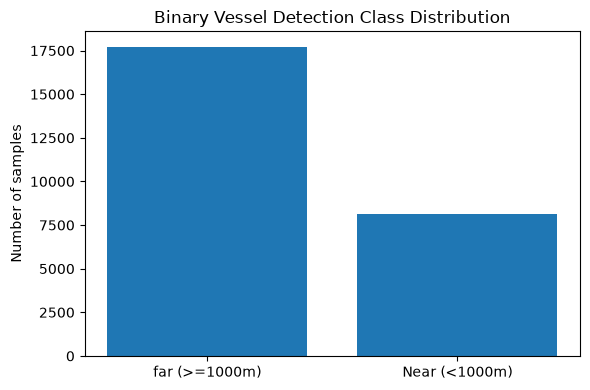

In [108]:
plt.figure(figsize=(6,4))
plt.bar(
    ["far (>=1000m)","Near (<1000m)"],
    [far_count,near_count]
)

plt.ylabel("Number of samples")
plt.title("Binary Vessel Detection Class Distribution")

plt.tight_layout()

results_figures=PROJECT_ROOT/"results"/"figures"
results_figures.mkdir(parents=True,exist_ok=True)

plt.savefig(
    results_figures/"binary_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Selecting small dataset (2000 samples)**

In [109]:
Sample_size=2000
random_state=42

rng=np.random.default_rng(random_state)
sample_indices=rng.choice(len(X_clean),
                         size=Sample_size,
                         replace=False)

x_sample=X_clean[sample_indices]
y_sample=y_binary[sample_indices]

distance_sample=y_distance_raw[sample_indices]

print("X_sample shape:", x_sample.shape)
print("Y_sample shape:", y_sample.shape)

X_sample_max=x_sample.max(axis=1)
print("New shape: ",X_sample_max.shape)

X_sample shape: (2000, 247, 100)
Y_sample shape: (2000,)
New shape:  (2000, 100)


In [110]:
sample_far=np.sum(y_sample==0)
sample_near=np.sum(y_sample==1)

print("Sample Dataset")
print("--------------------------------")
print("Far: ",sample_far)
print("Near: ",sample_near)

print(f"Far percentage: {sample_far/len(y_sample)*100:.2f}%")
print(f"Near percentage: {sample_near/len(y_sample)*100:.2f}%")



Sample Dataset
--------------------------------
Far:  1336
Near:  664
Far percentage: 66.80%
Near percentage: 33.20%


In [111]:
x_sample=X_sample_max.astype(np.float32)
print("Data type: ",x_sample.dtype)

Data type:  float32


**Flatten data for ANN**

In [112]:
x_sample_flat=x_sample.reshape(
    x_sample.shape[0],
    -1
)
print("Original sample shape: ",x_sample.shape[1:])
print("ANN input shape: ",x_sample_flat.shape)

Original sample shape:  (100,)
ANN input shape:  (2000, 100)


In [113]:
x_sample_log = np.log10(X_sample_max + 1e-20)
x_sample_log=x_sample_log.astype(np.float32)
print("Data type: ",x_sample_log.dtype)


x_train,x_temp,y_train,y_temp=train_test_split(
    x_sample_log,y_sample,test_size=0.30,
    random_state=random_state,stratify=y_sample)

x_val,x_test,y_val,y_test=train_test_split(
    x_temp,y_temp,test_size=0.50,
    random_state=random_state,stratify=y_temp
)

print("Training:", x_train.shape)
print("Validation: ",x_val.shape)
print("Testing: ",x_test.shape)


Data type:  float32
Training: (1400, 100)
Validation:  (300, 100)
Testing:  (300, 100)


In [114]:
ss=StandardScaler()
x_train_scaled=ss.fit_transform(x_train)
x_val_scaled=ss.transform(x_val)
x_test_scaled=ss.transform(x_test)

print("Training mean: ",x_train_scaled.mean())
print("Training standard deviation: ",x_train_scaled.std())

Training mean:  6.1035155e-09
Training standard deviation:  1.0


**Creating PyTorch Dataset**

In [115]:
from typing import Any


class VesselDataset(Dataset):
    def __init__(self,X,y):
        self.X=torch.tensor(X,dtype=torch.float32)
        self.y=torch.tensor(y,dtype=torch.float32)
    
    def __len__(self):
        return len(self.y)
    
    def __getitem__(self, index) -> Any:
        return (self.X[index],self.y[index])
    

train_dataset=VesselDataset(x_train_scaled,y_train)
val_dataset=VesselDataset(x_val_scaled,y_val)
test_dataset=VesselDataset(x_test_scaled,y_test)

print("Training Samples: ",len(train_dataset))
print("Validation Samples: ",len(val_dataset))
print("Testing Samples: ",len(test_dataset))

Training Samples:  1400
Validation Samples:  300
Testing Samples:  300


**Loading the Sample Dataset**

In [116]:
BATCH_SIZE=64
train_loader=DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True)
val_loader=DataLoader(val_dataset,batch_size=BATCH_SIZE,shuffle=False)
test_loader=DataLoader(test_dataset,batch_size=BATCH_SIZE,shuffle=False)

In [117]:
#Checking GPU/CPU

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device",device)

Using device cuda


In [118]:
input_size=x_train_scaled.shape[1]
model=ANNModel(input_size=input_size,hidden1=256,hidden2=128,dropout=0.1)
model=model.to(device)
print(model)

ANNModel(
  (network): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=128, out_features=1, bias=True)
  )
)


**Loss Function**

In [119]:
num_far=(y_train==0).sum()
num_near=(y_train==1).sum()
pos_weight=torch.tensor([num_far/num_near]).to(device)
criterion=nn.BCEWithLogitsLoss(pos_weight=pos_weight)
print("pos_weight value: ",criterion.pos_weight)

pos_weight value:  tensor([2.0108], device='cuda:0', dtype=torch.float64)


**Optimizer**

In [120]:
Learning_rate=0.001

optimizer=torch.optim.Adam(model.parameters(),lr=Learning_rate)
print("Learning rate: ",Learning_rate)

Learning rate:  0.001


In [121]:
epochs=100

history=train_model(
    model=model,
    train_loader=train_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    epochs=epochs
)

Epoch 1/100| Loss: 0.6914
Epoch 2/100| Loss: 0.5043
Epoch 3/100| Loss: 0.4402
Epoch 4/100| Loss: 0.4134
Epoch 5/100| Loss: 0.3928
Epoch 6/100| Loss: 0.3745
Epoch 7/100| Loss: 0.3675
Epoch 8/100| Loss: 0.3504
Epoch 9/100| Loss: 0.3361
Epoch 10/100| Loss: 0.3283
Epoch 11/100| Loss: 0.3145
Epoch 12/100| Loss: 0.3070
Epoch 13/100| Loss: 0.3040
Epoch 14/100| Loss: 0.2735
Epoch 15/100| Loss: 0.2704
Epoch 16/100| Loss: 0.2533
Epoch 17/100| Loss: 0.2367
Epoch 18/100| Loss: 0.2336
Epoch 19/100| Loss: 0.2286
Epoch 20/100| Loss: 0.1987
Epoch 21/100| Loss: 0.1940
Epoch 22/100| Loss: 0.1988
Epoch 23/100| Loss: 0.2118
Epoch 24/100| Loss: 0.1926
Epoch 25/100| Loss: 0.1730
Epoch 26/100| Loss: 0.1803
Epoch 27/100| Loss: 0.1555
Epoch 28/100| Loss: 0.1430
Epoch 29/100| Loss: 0.1294
Epoch 30/100| Loss: 0.1239
Epoch 31/100| Loss: 0.1145
Epoch 32/100| Loss: 0.1147
Epoch 33/100| Loss: 0.1438
Epoch 34/100| Loss: 0.1179
Epoch 35/100| Loss: 0.1063
Epoch 36/100| Loss: 0.1058
Epoch 37/100| Loss: 0.1086
Epoch 38/1

**Ploting Training Loss**

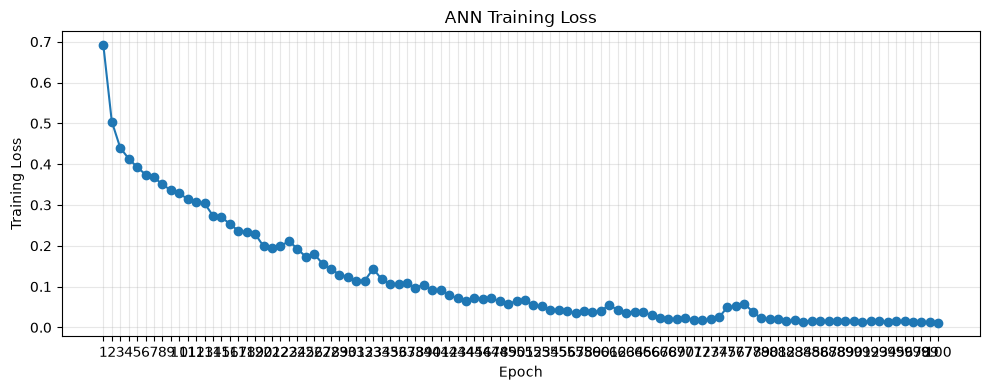

In [123]:
plt.figure(figsize=(10,4))
plt.plot(range(1,epochs+1),
         history["train_loss"],
         marker="o")

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("ANN Training Loss")

plt.xticks(range(1,epochs+1))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(results_figures/"small_ann_training_loss.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

**Evaluation**

In [124]:
y_true,y_pred,y_probabilities=predict_model(model=model,data_loader=test_loader,device=device)

In [125]:
import numpy as np
print("Unique values in y_true:", np.unique(y_true))
print("Unique values in y_pred:", np.unique(y_pred))
print("Prediction counts:", np.bincount(y_pred.astype(int).flatten()))

Unique values in y_true: [0. 1.]
Unique values in y_pred: [0 1]
Prediction counts: [197 103]


In [126]:
metrics=calculate_metrics(y_true,y_pred)
print("Small ANN Results")
print("-------------------------")
print(f"Accuracy: {metrics['accuracy']:.4f}")
print(f"Overall F1: {metrics['overall_f1']:.4f}")
print(f"Far F1: {metrics['far_f1']:.4f}")
print(f"Near F1 :{metrics['near_f1']:.4f}")

Small ANN Results
-------------------------
Accuracy: 0.8800
Overall F1: 0.8218
Far F1: 0.9095
Near F1 :0.8218


In [127]:
print(classification_report(y_true,y_pred,target_names=[
    "Far (>=1000m)",
    "Near (<1000m)"
],digits=4))

               precision    recall  f1-score   support

Far (>=1000m)     0.9188    0.9005    0.9095       201
Near (<1000m)     0.8058    0.8384    0.8218        99

     accuracy                         0.8800       300
    macro avg     0.8623    0.8694    0.8657       300
 weighted avg     0.8815    0.8800    0.8806       300



**Confusion matrix**

In [128]:
cm=confusion_matrix(y_true,y_pred)
print("Confusion matric: ")
print(cm)

Confusion matric: 
[[181  20]
 [ 16  83]]


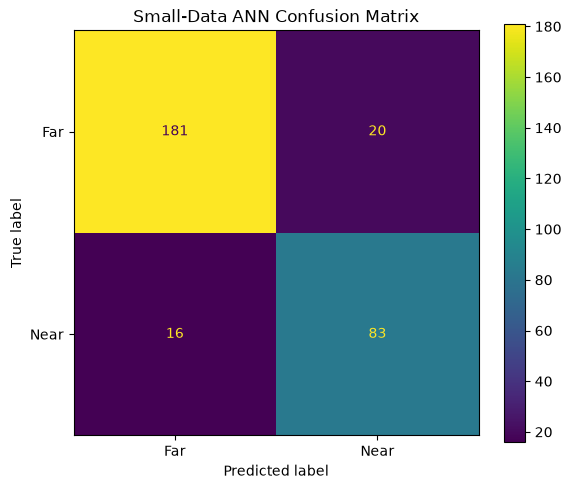

In [129]:
display=ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Far","Near"]
)
fig,ax=plt.subplots(figsize=(6,5))
display.plot(ax=ax)
ax.set_title("Small-Data ANN Confusion Matrix")
plt.tight_layout()
plt.savefig(results_figures/"Small_ann_confusion_matrix.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

In [ ]:
print("Probability stats:", y_probabilities.min(), y_probabilities.max(), y_probabilities.mean())
print("Near-class true probabilities:", y_probabilities[y_true == 1][:20])

In [53]:
print("Min:", x_train.min(), "Max:", x_train.max())
print("Mean:", x_train.mean(), "Std:", x_train.std())
print("Percentiles:", np.percentile(x_train, [1, 25, 50, 75, 99]))

Min: 1.443865e-14 Max: 0.00016477828
Mean: 1.4517505e-07 Std: 2.505422e-06
Percentiles: [2.20328227e-14 4.05712519e-14 6.56085158e-14 1.76155880e-13
 1.03511464e-06]


In [55]:
X_small_log = np.log10(X_sample_max + 1e-20)   # tiny epsilon avoids log(0) errors
print("Log10-transformed stats:")
print("Min:", X_small_log.min(), "Max:", X_small_log.max())
print("Percentiles:", np.percentile(X_small_log, [1, 25, 50, 75, 99]))

Log10-transformed stats:
Min: -13.840473113314927 Max: -3.7445283251135155
Percentiles: [-13.65658302 -13.39111931 -13.18178126 -12.75554879  -5.60315368]


In [72]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

for clf in [LogisticRegression(max_iter=1000, class_weight="balanced"),
            RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)]:
    clf.fit(x_train_scaled, y_train)
    pred = clf.predict(x_test_scaled)
    print(type(clf).__name__, "near F1:", f1_score(y_test, pred))

LogisticRegression near F1: 0.038834951456310676
RandomForestClassifier near F1: 0.8324873096446701


In [98]:
print("Input max abs:", np.abs(x_train_scaled).max())

model.eval()
with torch.no_grad():
    out = model(torch.tensor(x_test_scaled[:200], dtype=torch.float32).to(device))
print("Output std across samples:", out.std().item())

Input max abs: 27.31246
Output std across samples: 3.5885417461395264


In [99]:
from sklearn.metrics import roc_auc_score
print("AUC:", roc_auc_score(y_true, y_probabilities.flatten()))

AUC: 0.5099753756470174


In [100]:
Xb, yb = next(iter(train_loader))
Xb, yb = Xb.to(device), yb.to(device)

m = ANNModel(input_size=Xb.shape[1], hidden1=256, hidden2=128, dropout=0.0).to(device)
opt = torch.optim.Adam(m.parameters(), lr=0.001)
crit = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

for step in range(300):
    opt.zero_grad()
    loss = crit(m(Xb), yb)
    loss.backward()
    opt.step()
print("Final loss on one batch:", loss.item())

Final loss on one batch: 0.881026566028595


In [101]:
from sklearn.preprocessing import QuantileTransformer

qt = QuantileTransformer(output_distribution="normal", random_state=42)
xq_train = qt.fit_transform(x_train).astype(np.float32)

Xb = torch.tensor(xq_train[:64]).to(device)
yb = torch.tensor(y_train[:64], dtype=torch.float32).to(device)

m = ANNModel(input_size=Xb.shape[1], hidden1=256, hidden2=128, dropout=0.0).to(device)
opt = torch.optim.Adam(m.parameters(), lr=0.001)
crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([2.0], device=device))

for step in range(300):
    opt.zero_grad()
    loss = crit(m(Xb), yb)
    loss.backward()
    opt.step()
print("Final loss on one batch:", loss.item())

Final loss on one batch: 0.8507570028305054


In [102]:
print("Xb:", Xb.shape, "NaN:", torch.isnan(Xb).any().item(), "std:", Xb.std().item())
print("yb counts:", yb.sum().item(), "near of", len(yb))

plain = nn.Sequential(
    nn.Linear(Xb.shape[1], 256), nn.ReLU(),
    nn.Linear(256, 128), nn.ReLU(),
    nn.Linear(128, 1)
).to(device)
opt = torch.optim.Adam(plain.parameters(), lr=0.001)
crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([2.0], device=device))

for step in range(300):
    opt.zero_grad()
    loss = crit(plain(Xb).squeeze(1), yb)
    loss.backward()
    opt.step()
print("Plain network loss:", loss.item())

Xb: torch.Size([64, 100]) NaN: False std: 1.69291090965271
yb counts: 19.0 near of 64
Plain network loss: 0.8507581949234009


In [103]:
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score

# 1) How many independent directions are in the 100 features?
p = PCA().fit(x_train_scaled)
print("Variance explained, first 5 components:", p.explained_variance_ratio_[:5].round(3))
print("Unique rows in the 64-sample batch:", torch.unique(Xb, dim=0).shape[0])

# 2) Same 64 samples, CPU, 10x more steps, higher learning rate
Xc, yc = Xb.cpu(), yb.cpu()
net = nn.Sequential(nn.Linear(100, 256), nn.ReLU(), nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 1))
opt = torch.optim.Adam(net.parameters(), lr=0.003)
crit = nn.BCEWithLogitsLoss()
for step in range(3000):
    opt.zero_grad()
    loss = crit(net(Xc).squeeze(1), yc)
    loss.backward()
    opt.step()
print("CPU one-batch final loss:", loss.item())

# 3) Does any neural net learn from the full training set?
mlp = MLPClassifier(hidden_layer_sizes=(256, 128), max_iter=300, random_state=42)
mlp.fit(x_train_scaled, y_train)
print("MLP AUC:", roc_auc_score(y_test, mlp.predict_proba(x_test_scaled)[:, 1]))

Variance explained, first 5 components: [0.845 0.024 0.019 0.016 0.015]
Unique rows in the 64-sample batch: 4
CPU one-batch final loss: 0.5782032608985901
MLP AUC: 0.861148801447309
